<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/Micro_price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================================
# MICRO-PRICE PREDICTION
# PART 1 : DATA PREPROCESSING & LABEL CREATION
# ==========================================================

import pandas as pd
import numpy as np

from google.colab import files
from sklearn.preprocessing import StandardScaler

# ----------------------------------------------------------
# Upload Dataset
# ----------------------------------------------------------

uploaded = files.upload()

depth = pd.read_csv("BTCUSDT_Depth_1Hour.csv")

print("Dataset Shape :", depth.shape)

# ----------------------------------------------------------
# Calculate Micro-Price
# ----------------------------------------------------------

depth["micro_price"] = (
    depth["best_ask"] * depth["best_bid_qty"] +
    depth["best_bid"] * depth["best_ask_qty"]
) / (
    depth["best_bid_qty"] +
    depth["best_ask_qty"]
)

# ----------------------------------------------------------
# Future Micro-Price
# ----------------------------------------------------------

prediction_horizon = 5

depth["future_micro_price"] = (
    depth["micro_price"].shift(-prediction_horizon)
)

# ----------------------------------------------------------
# Future Return
# ----------------------------------------------------------

depth["future_return"] = (
    depth["future_micro_price"] -
    depth["micro_price"]
) / depth["micro_price"]

# ----------------------------------------------------------
# Balanced Labels using Quantiles
# ----------------------------------------------------------

lower = depth["future_return"].quantile(0.33)
upper = depth["future_return"].quantile(0.66)

depth["label"] = np.where(
    depth["future_return"] < lower,
    0,
    np.where(
        depth["future_return"] > upper,
        2,
        1
    )
)

# ----------------------------------------------------------
# Remove Missing Rows
# ----------------------------------------------------------

depth.dropna(inplace=True)
depth.reset_index(drop=True, inplace=True)

# ----------------------------------------------------------
# Label Distribution
# ----------------------------------------------------------

print("\nLabel Distribution")
print(depth["label"].value_counts().sort_index())

print("\nLabel Percentage")
print(
    (
        depth["label"]
        .value_counts(normalize=True)
        .sort_index()
        *100
    ).round(2)
)

# ----------------------------------------------------------
# Feature Columns
# ----------------------------------------------------------

feature_columns = []

for i in range(1,11):

    feature_columns.extend([

        f"bid_price_{i}",
        f"bid_qty_{i}",
        f"ask_price_{i}",
        f"ask_qty_{i}"

    ])

# ----------------------------------------------------------
# Feature Matrix
# ----------------------------------------------------------

X = depth[feature_columns].values

y = depth["label"].values.astype(int)

# ----------------------------------------------------------
# Standardization
# ----------------------------------------------------------

scaler = StandardScaler()

X = scaler.fit_transform(X)

# ----------------------------------------------------------
# Final Checks
# ----------------------------------------------------------

print("\nFeature Matrix Shape :", X.shape)
print("Target Shape         :", y.shape)

print("\nUnique Labels")
print(np.unique(y, return_counts=True))

print("\nMicro-Price Sample")
print(depth[[
    "micro_price",
    "future_micro_price",
    "future_return",
    "label"
]].head())

print("\n✅ PART 1 COMPLETED SUCCESSFULLY")

Saving BTCUSDT_Depth_1Hour.csv to BTCUSDT_Depth_1Hour.csv
Dataset Shape : (35901, 45)

Label Distribution
label
0    2476
1    3199
2    2592
Name: count, dtype: int64

Label Percentage
label
0    29.95
1    38.70
2    31.35
Name: proportion, dtype: float64

Feature Matrix Shape : (8267, 40)
Target Shape         : (8267,)

Unique Labels
(array([0, 1, 2]), array([2476, 3199, 2592]))

Micro-Price Sample
    micro_price  future_micro_price  future_return  label
0  61130.990000        61136.640342   9.243007e-05      2
1  61132.000000        61138.230000   1.019106e-04      2
2  61136.640753        61136.650000   1.512556e-07      1
3  61136.640530        61141.096066   7.287832e-05      2
4  61136.640342        61141.095119   7.286591e-05      2

✅ PART 1 COMPLETED SUCCESSFULLY


In [ ]:
# ==========================================================
# PART 2 : SEQUENCE GENERATION
# ==========================================================

import numpy as np
from sklearn.model_selection import train_test_split

# ----------------------------------------------------------
# Sequence Length
# ----------------------------------------------------------

sequence_length = 50

X_seq = []
y_seq = []

# ----------------------------------------------------------
# Create Sequences
# ----------------------------------------------------------

for i in range(len(X) - sequence_length):

    X_seq.append(X[i:i + sequence_length])

    # Predict movement AFTER the sequence
    y_seq.append(y[i + sequence_length])

X_seq = np.array(X_seq)
y_seq = np.array(y_seq)

print("="*60)
print("SEQUENCE INFORMATION")
print("="*60)

print("Sequence Shape :", X_seq.shape)
print("Label Shape    :", y_seq.shape)

print("\nSequence Label Distribution")
print(np.unique(y_seq, return_counts=True))

# ----------------------------------------------------------
# Reshape for CNN
# ----------------------------------------------------------

X_seq = X_seq.reshape(
    X_seq.shape[0],
    sequence_length,
    X.shape[1],
    1
)

print("\nCNN Input Shape :", X_seq.shape)

# ----------------------------------------------------------
# Train-Test Split
# ----------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X_seq,
    y_seq,
    test_size=0.20,
    random_state=42,
    stratify=y_seq
)

print("\nTraining Samples :", X_train.shape[0])
print("Testing Samples  :", X_test.shape[0])

print("\nTraining Labels")
print(np.unique(y_train, return_counts=True))

print("\nTesting Labels")
print(np.unique(y_test, return_counts=True))

print("\n✅ PART 2 COMPLETED SUCCESSFULLY")

SEQUENCE INFORMATION
Sequence Shape : (8217, 50, 40)
Label Shape    : (8217,)

Sequence Label Distribution
(array([0, 1, 2]), array([2470, 3172, 2575]))

CNN Input Shape : (8217, 50, 40, 1)

Training Samples : 6573
Testing Samples  : 1644

Training Labels
(array([0, 1, 2]), array([1976, 2537, 2060]))

Testing Labels
(array([0, 1, 2]), array([494, 635, 515]))

✅ PART 2 COMPLETED SUCCESSFULLY


In [ ]:
!pip install -q optuna

In [ ]:
# ==========================================================
# PART 3 : OPTUNA HYPERPARAMETER OPTIMIZATION
# ==========================================================

import optuna
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    BatchNormalization,
    MaxPooling2D,
    TimeDistributed,
    Flatten,
    LSTM,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import EarlyStopping

# ----------------------------------------------------------
# Objective Function
# ----------------------------------------------------------

def objective(trial):

    filters = trial.suggest_categorical(
        "filters",
        [16, 32, 64]
    )

    lstm_units = trial.suggest_categorical(
        "lstm_units",
        [32, 64, 128]
    )

    dense_units = trial.suggest_categorical(
        "dense_units",
        [16, 32, 64]
    )

    dropout = trial.suggest_float(
        "dropout",
        0.20,
        0.50
    )

    learning_rate = trial.suggest_float(
        "learning_rate",
        1e-4,
        1e-2,
        log=True
    )

    batch_size = trial.suggest_categorical(
        "batch_size",
        [64, 128, 256]
    )

    model = Sequential([

        Input(shape=(50,40,1)),

        Conv2D(
            filters,
            (1,2),
            activation="relu",
            padding="same"
        ),

        BatchNormalization(),

        Conv2D(
            filters,
            (1,2),
            activation="relu",
            padding="same"
        ),

        BatchNormalization(),

        MaxPooling2D(pool_size=(1,2)),

        TimeDistributed(Flatten()),

        LSTM(lstm_units),

        Dropout(dropout),

        Dense(
            dense_units,
            activation="relu"
        ),

        Dense(3, activation="softmax")

    ])

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    history = model.fit(

        X_train,
        y_train,

        validation_data=(X_test, y_test),

        epochs=10,

        batch_size=batch_size,

        callbacks=[early_stop],

        verbose=0

    )

    return max(history.history["val_accuracy"])

# ----------------------------------------------------------
# Run Optuna
# ----------------------------------------------------------

study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=10
)

print("="*60)
print("BEST HYPERPARAMETERS")
print("="*60)

print(study.best_params)

print("\nBest Validation Accuracy:")
print(study.best_value)

[I 2026-07-28 06:24:38,237] A new study created in memory with name: no-name-04f3c682-551a-4522-b82f-0e361b23153f
[I 2026-07-28 06:24:58,257] Trial 0 finished with value: 0.4781021773815155 and parameters: {'filters': 32, 'lstm_units': 128, 'dense_units': 32, 'dropout': 0.427395395635389, 'learning_rate': 0.008924303234259202, 'batch_size': 128}. Best is trial 0 with value: 0.4781021773815155.
[I 2026-07-28 06:25:21,722] Trial 1 finished with value: 0.44403892755508423 and parameters: {'filters': 32, 'lstm_units': 32, 'dense_units': 16, 'dropout': 0.4883854082395763, 'learning_rate': 0.005183104797390183, 'batch_size': 256}. Best is trial 0 with value: 0.4781021773815155.
[I 2026-07-28 06:25:31,740] Trial 2 finished with value: 0.3363747000694275 and parameters: {'filters': 16, 'lstm_units': 64, 'dense_units': 16, 'dropout': 0.2873257853571146, 'learning_rate': 0.00018350120722469742, 'batch_size': 256}. Best is trial 0 with value: 0.4781021773815155.
[I 2026-07-28 06:25:51,708] Trial 

BEST HYPERPARAMETERS
{'filters': 32, 'lstm_units': 64, 'dense_units': 32, 'dropout': 0.24520397362477453, 'learning_rate': 0.00021200120273801514, 'batch_size': 64}

Best Validation Accuracy:
0.4945255517959595


In [ ]:

# ==========================================================
# PART 4 : TRAIN FINAL OPTIMIZED MODEL
# ==========================================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    BatchNormalization,
    MaxPooling2D,
    TimeDistributed,
    Flatten,
    LSTM,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# ----------------------------------------------------------
# Best Parameters from Optuna
# ----------------------------------------------------------

best = study.best_params

print("="*60)
print("BEST PARAMETERS")
print("="*60)

for key, value in best.items():
    print(f"{key}: {value}")

# ----------------------------------------------------------
# Build Final Model
# ----------------------------------------------------------

model = Sequential([

    Input(shape=(50, 40, 1)),

    Conv2D(
        filters=best["filters"],
        kernel_size=(1, 2),
        activation="relu",
        padding="same"
    ),

    BatchNormalization(),

    Conv2D(
        filters=best["filters"],
        kernel_size=(1, 2),
        activation="relu",
        padding="same"
    ),

    BatchNormalization(),

    MaxPooling2D(pool_size=(1,2)),

    TimeDistributed(Flatten()),

    LSTM(best["lstm_units"]),

    Dropout(best["dropout"]),

    Dense(
        best["dense_units"],
        activation="relu"
    ),

    Dense(3, activation="softmax")

])

optimizer = tf.keras.optimizers.Adam(
    learning_rate=best["learning_rate"]
)

model.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ----------------------------------------------------------
# Callbacks
# ----------------------------------------------------------

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_microprice_model.keras",
    save_best_only=True,
    monitor="val_accuracy",
    verbose=1
)

# ----------------------------------------------------------
# Train Final Model
# ----------------------------------------------------------

history = model.fit(

    X_train,
    y_train,

    validation_data=(X_test, y_test),

    epochs=30,

    batch_size=best["batch_size"],

    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ],

    verbose=1

)

print("\nTraining Completed Successfully!")
print("Best Validation Accuracy:",
      max(history.history["val_accuracy"]))

BEST PARAMETERS
filters: 32
lstm_units: 64
dense_units: 32
dropout: 0.24520397362477453
learning_rate: 0.00021200120273801514
batch_size: 64
Epoch 1/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.3996 - loss: 1.0784
Epoch 1: val_accuracy improved from None to 0.38078, saving model to best_microprice_model.keras

Epoch 1: finished saving model to best_microprice_model.keras
103/103 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - accuracy: 0.4255 - loss: 1.0586 - val_accuracy: 0.3808 - val_loss: 1.0939 - learning_rate: 2.1200e-04
Epoch 2/30
102/103 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4641 - loss: 1.0178
Epoch 2: val_accuracy improved from 0.38078 to 0.41119, saving model to best_microprice_model.keras

Epoch 2: finished saving model to best_microprice_model.keras
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.4602 - loss: 1.0216 - val_accuracy: 0.4112 - val_loss: 1.0722 - learning_rate: 2.1200e-04
Epoch 3/30
102/103 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.475

52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step
MICRO-PRICE PREDICTION RESULTS
Accuracy : 0.4799
Precision: 0.4834
Recall   : 0.4799
F1 Score : 0.4802

Classification Report

              precision    recall  f1-score   support

           0       0.48      0.50      0.49       494
           1       0.45      0.49      0.47       635
           2       0.53      0.45      0.49       515

    accuracy                           0.48      1644
   macro avg       0.49      0.48      0.48      1644
weighted avg       0.48      0.48      0.48      1644


Confusion Matrix

[[245 191  58]
 [175 313 147]
 [ 94 190 231]]


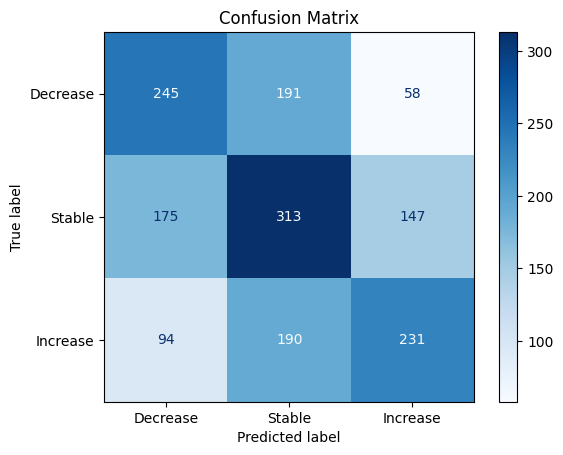

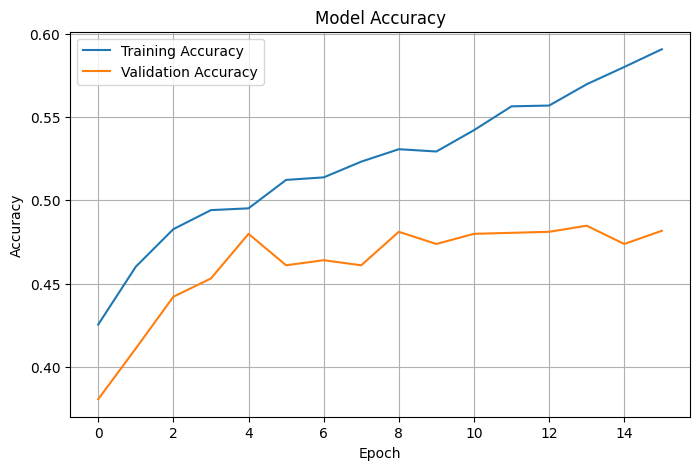

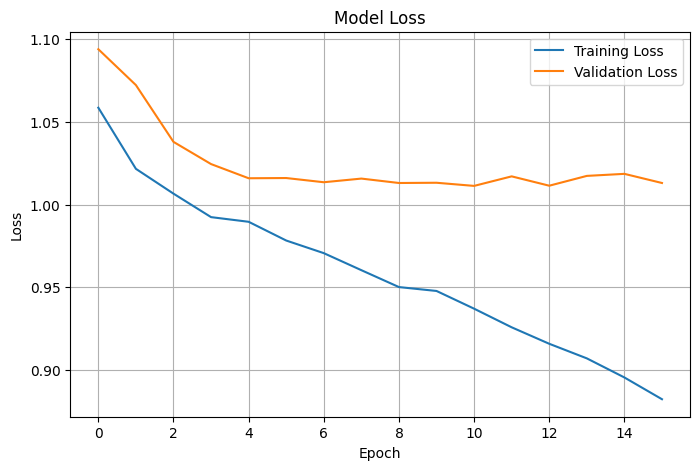


PROJECT SUMMARY
Model               : CNN + LSTM
Hyperparameter Tuning: Optuna
Input Features      : 40 Level-10 LOB Features
Sequence Length     : 50
Prediction Horizon  : 5
Target              : Micro-Price Movement
Classes             : 3
Optimizer           : Adam
Loss Function       : Sparse Categorical Crossentropy


In [ ]:
# ==========================================================
# PART 5 : MODEL EVALUATION
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ----------------------------------------------------------
# Predictions
# ----------------------------------------------------------

y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)

# ----------------------------------------------------------
# Metrics
# ----------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("="*60)
print("MICRO-PRICE PREDICTION RESULTS")
print("="*60)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

print("\nClassification Report\n")
print(classification_report(y_test, y_pred))

# ----------------------------------------------------------
# Confusion Matrix
# ----------------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix\n")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Decrease",
        "Stable",
        "Increase"
    ]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ----------------------------------------------------------
# Accuracy Curve
# ----------------------------------------------------------

plt.figure(figsize=(8,5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Model Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

# ----------------------------------------------------------
# Loss Curve
# ----------------------------------------------------------

plt.figure(figsize=(8,5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Model Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

# ----------------------------------------------------------
# Final Summary
# ----------------------------------------------------------

print("\n" + "="*60)
print("PROJECT SUMMARY")
print("="*60)

print("Model               : CNN + LSTM")
print("Hyperparameter Tuning: Optuna")
print("Input Features      : 40 Level-10 LOB Features")
print("Sequence Length     :", sequence_length)
print("Prediction Horizon  :", prediction_horizon)
print("Target              : Micro-Price Movement")
print("Classes             : 3")
print("Optimizer           : Adam")
print("Loss Function       : Sparse Categorical Crossentropy")
print("="*60)

In [ ]:
for i in range(10):
    print(
        f"Actual: {y_test[i]} | Predicted: {y_pred[i]}"
    )

Actual: 2 | Predicted: 2
Actual: 0 | Predicted: 2
Actual: 0 | Predicted: 0
Actual: 0 | Predicted: 0
Actual: 2 | Predicted: 1
Actual: 2 | Predicted: 1
Actual: 1 | Predicted: 0
Actual: 1 | Predicted: 0
Actual: 2 | Predicted: 2
Actual: 0 | Predicted: 2


In [ ]:
signals = np.where(y_pred == 2, "BUY",
          np.where(y_pred == 0, "SELL", "HOLD"))

print(signals[:20])

['BUY' 'BUY' 'SELL' 'SELL' 'HOLD' 'HOLD' 'SELL' 'SELL' 'BUY' 'BUY' 'SELL'
 'BUY' 'BUY' 'SELL' 'SELL' 'SELL' 'BUY' 'SELL' 'SELL' 'HOLD']


In [ ]:
profits = np.array(profits)

valid = ~np.isnan(profits)

profits = profits[valid]

signals = signals[valid]

In [ ]:
total_profit = profits.sum()
average_profit = profits.mean()

wins = np.sum(profits > 0)
losses = np.sum(profits < 0)

total_trades = len(profits)
win_rate = wins / total_trades * 100

In [ ]:
# ==========================================================
# PERFORMANCE METRICS
# ==========================================================

total_trades = np.sum(signals != 1)

wins = np.sum(np.array(profits) > 0)

losses = np.sum(np.array(profits) < 0)

win_rate = wins / total_trades * 100 if total_trades else 0

total_profit = np.sum(profits)

average_profit = np.mean(profits)

print("="*60)
print("BACKTEST RESULTS")
print("="*60)

print("Total Trades :", total_trades)
print("Winning Trades :", wins)
print("Losing Trades :", losses)
print(f"Win Rate : {win_rate:.2f}%")
print(f"Total Profit : {total_profit:.4f}")
print(f"Average Profit/Trade : {average_profit:.6f}")

BACKTEST RESULTS
Total Trades : 917
Winning Trades : 91
Losing Trades : 821
Win Rate : 9.92%
Total Profit : -221993.8500
Average Profit/Trade : -138.141786
